# Séance 5 — Variables temporelles

**Durée pratique : 2 h** &nbsp;·&nbsp; Ateliers 5.1 à 5.3

## Ce que vous saurez faire à la fin

- parser des dates hétérogènes sans perdre de lignes silencieusement ;
- extraire des variables calendaires exploitables en analyse et en BI ;
- rééchantillonner une série et calculer des moyennes mobiles.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name in ('notebooks', 'Notebook') else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


---
## Atelier 5.1 — Parser des dates hétérogènes (35 min)

### Partie guidée

In [2]:
raw_sales = pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
print(raw_sales['date_commande'].dropna().sample(10, random_state=1).tolist())

['2023-01-31', '15 Apr 2024', '07 Apr 2023', '2024/02/06 16:05', '2023/09/09 20:40', '2023-05-08', '08 Dec 2023', '07 Feb 2023', '01/11/2024', '06 Sep 2024']


Cinq formats coexistent dans la même colonne. Le piège est réel : `05/03/2024` peut se lire
5 mars ou 3 mai selon la convention. Une erreur ici déplace des milliers de lignes de mois
sans qu'aucune exception ne soit levée.

In [3]:
# format='mixed' laisse pandas inférer ligne par ligne ; dayfirst lève l'ambiguïté jj/mm
order_dates = pd.to_datetime(raw_sales['date_commande'],
                             format='mixed', dayfirst=True, errors='coerce')

n_missing_before = raw_sales['date_commande'].isna().sum()
n_missing_after = order_dates.isna().sum()

print('Valeurs initialement absentes  :', n_missing_before)
print('Valeurs absentes après parsing :', n_missing_after)
print('Échecs de conversion           :', n_missing_after - n_missing_before)
print('Plage couverte :', order_dates.min(), '->', order_dates.max())

Valeurs initialement absentes  : 350
Valeurs absentes après parsing : 350
Échecs de conversion           : 0
Plage couverte : 2023-01-01 00:00:00 -> 2024-12-30 17:10:00


**`errors='coerce'` transforme les échecs en `NaT` au lieu de lever une exception.** C'est
commode, mais dangereux si vous ne comptez pas les échecs juste après. Une conversion qui
détruit 8 % des dates sans le signaler est une bombe à retardement.

### Partie autonome

In [4]:
# Q1. Écrire une fonction parse_dates(series) qui renvoie (series_converties, report)
#     où report est un dict : n_total, n_already_missing, n_failed, success_rate,
#     min_date, max_date. Levez une ValueError si le taux de réussite est inférieur
#     à un seuil passé en paramètre (défaut 0,95).

def parse_dates(series, min_success_rate=0.95):
    ...  # TODO
    """Convertit une série de dates hétérogènes et renvoie (dates, rapport).

    Lève une ValueError si le taux de réussite est inférieur au seuil.
    """
    converted = pd.to_datetime(series, format='mixed', dayfirst=True, errors='coerce')

    n_total = len(series)
    n_already_missing = int(series.isna().sum())
    n_failed = int(converted.isna().sum()) - n_already_missing
    n_to_parse = n_total - n_already_missing
    success_rate = (n_to_parse - n_failed) / n_to_parse if n_to_parse else 1.0

    report = {
        'n_total': n_total,
        'n_already_missing': n_already_missing,
        'n_failed': n_failed,
        'success_rate': round(success_rate, 4),
        'min_date': converted.min(),
        'max_date': converted.max(),
    }

    if success_rate < min_success_rate:
        raise ValueError(f'Taux de réussite {success_rate:.1%} inférieur au seuil {min_success_rate:.0%}')

    return converted, report


# order_dates, report = parse_dates(raw_sales['date_commande'])
# print(report)
order_dates, report = parse_dates(raw_sales['date_commande'])
for key, value in report.items():
    print(f'  {key:<18} {value}')

  n_total            17609
  n_already_missing  350
  n_failed           0
  success_rate       1.0
  min_date           2023-01-01 00:00:00
  max_date           2024-12-30 17:10:00


---
## Atelier 5.2 — Variables calendaires (45 min)

### Partie guidée

In [5]:
if dataset_exists('ventes_transformees'):
    sales = load_dataset('ventes_transformees')
else:
    sales = raw_sales.assign(date_commande=order_dates).dropna(subset=['date_commande'])

sales['date_commande'] = pd.to_datetime(sales['date_commande'], errors='coerce')
sales = sales.dropna(subset=['date_commande'])

date_accessor = sales['date_commande'].dt
sales['annee'] = date_accessor.year
sales['mois'] = date_accessor.month
sales['jour_semaine'] = date_accessor.dayofweek          # 0 = lundi
sales['nom_jour'] = date_accessor.day_name()
sales['semaine_iso'] = date_accessor.isocalendar().week.astype(int)
sales['trimestre'] = date_accessor.quarter
sales['heure'] = date_accessor.hour
sales['est_weekend'] = sales['jour_semaine'] >= 5

sales[['date_commande', 'annee', 'mois', 'nom_jour', 'semaine_iso', 'est_weekend']].head()

,date_commande,annee,mois,nom_jour,semaine_iso,est_weekend
0,2024-01-18 19:53:00,2024,1,Thursday,3,False
1,2024-01-08 00:00:00,2024,1,Monday,2,False
2,2023-04-15 00:00:00,2023,4,Saturday,15,True
3,2024-11-06 00:00:00,2024,11,Wednesday,45,False
4,2024-02-11 00:00:00,2024,2,Sunday,6,True


**`isocalendar().week` plutôt que `.week`.** La semaine ISO gère correctement les jours de
fin décembre appartenant à la semaine 1 de l'année suivante. C'est exactement le genre de
détail qui produit des écarts inexplicables entre deux tableaux de bord.

In [6]:
# Encodage cyclique : le mois 12 est adjacent au mois 1, ce qu'un entier ne dit pas
sales['mois_sin'] = np.sin(2 * np.pi * sales['mois'] / 12)
sales['mois_cos'] = np.cos(2 * np.pi * sales['mois'] / 12)

cyclic = sales.groupby('mois')[['mois_sin', 'mois_cos']].first().round(3)
print(cyclic)
print()
print('Distance entre décembre et janvier :',
      round(float(np.hypot(*(cyclic.loc[12] - cyclic.loc[1]))), 3))
print('Distance entre janvier et février  :',
      round(float(np.hypot(*(cyclic.loc[1] - cyclic.loc[2]))), 3))

      mois_sin  mois_cos
mois                    
1        0.500     0.866
2        0.866     0.500
3        1.000     0.000
4        0.866    -0.500
5        0.500    -0.866
6        0.000    -1.000
7       -0.500    -0.866
8       -0.866    -0.500
9       -1.000    -0.000
10      -0.866     0.500
11      -0.500     0.866
12      -0.000     1.000

Distance entre décembre et janvier : 0.518
Distance entre janvier et février  : 0.518


### Partie autonome

In [7]:
# Q2. Ajouter les variables suivantes :
#     - periode_journee : 'matin' (<12), 'apres-midi' (12-17), 'soir' (>=18) ;
#     - est_fin_de_mois : les trois derniers jours du mois ;
#     - jours_depuis_debut : nombre de jours écoulés depuis la première commande ;
#     - anciennete_client_jours : écart entre la date de commande et la date d'inscription
#       du client (nécessite une jointure avec clients.csv).

# TODO
# Période de la journée. Attention : beaucoup de dates n'ont pas d'heure dans la source
# (format jj/mm/aaaa) et sont lues à minuit ; elles tombent mécaniquement dans 'matin'.
sales['periode_journee'] = pd.cut(sales['heure'], bins=[-1, 11, 17, 23],
                                  labels=['matin', 'apres-midi', 'soir']).astype(str)

# Fin de mois : les trois derniers jours, quelle que soit la longueur du mois
sales['est_fin_de_mois'] = date_accessor.day > (date_accessor.days_in_month - 3)

# Jours écoulés depuis la première commande du jeu
sales['jours_depuis_debut'] = (sales['date_commande'] - sales['date_commande'].min()).dt.days

# Ancienneté du client au moment de la commande (jointure sur la clé, non normalisée)
customers = pd.read_csv(RAW_DIR / 'clients.csv', parse_dates=['date_inscription'])
sales = sales.merge(customers[['id_client', 'date_inscription']], on='id_client', how='left')
sales['anciennete_client_jours'] = (sales['date_commande'] - sales['date_inscription']).dt.days

print(sales['periode_journee'].value_counts())
print()
print('Commandes en fin de mois :', sales['est_fin_de_mois'].mean().round(3))
print('Clients non retrouvés    :', sales['date_inscription'].isna().sum())
print('Anciennetés négatives    :', (sales['anciennete_client_jours'] < 0).sum(),
      '(commande antérieure à l\'inscription : incohérence à signaler)')
sales[['date_commande', 'periode_journee', 'est_fin_de_mois',
       'jours_depuis_debut', 'anciennete_client_jours']].head()

periode_journee
matin         14594
apres-midi     1570
soir            828
Name: count, dtype: int64

Commandes en fin de mois : 0.092
Clients non retrouvés    : 0
Anciennetés négatives    : 1739 (commande antérieure à l'inscription : incohérence à signaler)


,date_commande,periode_journee,est_fin_de_mois,jours_depuis_debut,anciennete_client_jours
0,2024-01-18 19:53:00,soir,False,382,1005
1,2024-01-08 00:00:00,matin,False,372,-42
2,2023-04-15 00:00:00,matin,False,104,1511
3,2024-11-06 00:00:00,matin,False,675,1985
4,2024-02-11 00:00:00,matin,False,406,1135


In [8]:
# Q3. Le chiffre d'affaires est-il différent le week-end ? Comparez le montant moyen
#     par commande selon est_weekend, puis selon le nom du jour. Commentez.

# TODO
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

print('Montant par commande selon est_weekend :')
print(sales.groupby('est_weekend')['montant'].agg(['mean', 'median', 'size']).round(2))
print()
print('Montant par commande selon le jour :')
print(sales.groupby('nom_jour')['montant'].agg(['mean', 'median', 'size']).reindex(day_order).round(2))
# Commentaire : la moyenne est nettement plus élevée le week-end (surtout le dimanche),
# mais la médiane est quasiment identique tous les jours (~950 EUR). L'écart de moyenne
# vient donc de quelques commandes aux quantités extrêmes tombées le week-end, pas d'un
# comportement d'achat différent. Le nombre de commandes par jour est lui aussi stable.
# Conclusion : pas d'effet week-end réel sur le panier ; comparer des moyennes sur une
# variable aussi asymétrique est trompeur, la médiane est ici le bon indicateur.

Montant par commande selon est_weekend :
                mean  median   size
est_weekend                        
False        2093.99  958.28  12262
True         3602.39  969.54   4730

Montant par commande selon le jour :
              mean   median  size
nom_jour                         
Monday     1738.36   961.99  2513
Tuesday    2042.24   943.37  2440
Wednesday  2163.77   938.02  2383
Thursday   2208.00   958.07  2423
Friday     2324.70  1001.42  2503
Saturday   2830.33   951.69  2329
Sunday     4351.31   989.22  2401


---
## Atelier 5.3 — Rééchantillonnage et fenêtres glissantes (40 min)

Le jeu `capteurs.csv` contient trois séries horaires sur dix-huit mois, avec une panne de
onze jours, un capteur bloqué sur une valeur constante et des horodatages dupliqués.

In [9]:
sensors = pd.read_csv(RAW_DIR / 'capteurs.csv', parse_dates=['horodatage'])

print(sensors.shape)
print(sensors['id_capteur'].value_counts())
print('Doublons (capteur, horodatage) :',
      sensors.duplicated(['id_capteur', 'horodatage']).sum())

(38916, 5)
id_capteur
CAP-C    13070
CAP-A    13069
CAP-B    12777
Name: count, dtype: int64
Doublons (capteur, horodatage) : 300


In [10]:
# Nettoyage minimal avant toute analyse temporelle
sensors = sensors.drop_duplicates(['id_capteur', 'horodatage'])
sensors['humidite_pct'] = sensors['humidite_pct'].replace(-999, np.nan)

sensor_a = (sensors[sensors['id_capteur'] == 'CAP-A']
            .set_index('horodatage')
            .sort_index())

daily_temperature = sensor_a['temperature_c'].resample('D').mean()
print(daily_temperature.head())
print('\nJours sans aucune mesure :', daily_temperature.isna().sum())

horodatage
2024-01-01    3.515000
2024-01-02    3.279130
2024-01-03    2.618261
2024-01-04    2.894348
2024-01-05    3.340435
Freq: D, Name: temperature_c, dtype: float64

Jours sans aucune mesure : 0


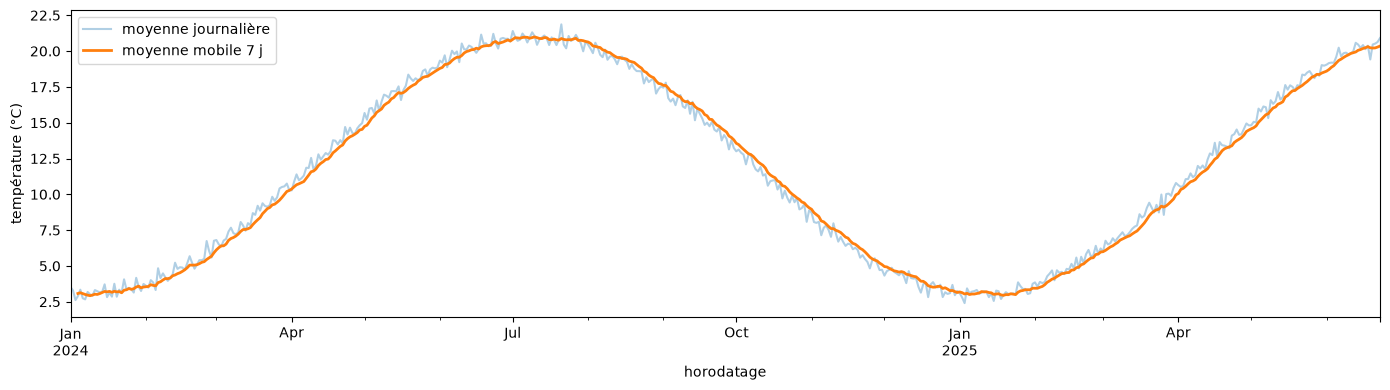

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 4))
daily_temperature.plot(ax=ax, alpha=0.35, label='moyenne journalière')
(daily_temperature.rolling(7, min_periods=4).mean()
 .plot(ax=ax, linewidth=2, label='moyenne mobile 7 j'))
ax.set_ylabel('température (°C)')
ax.legend()
plt.tight_layout()
plt.show()

`min_periods=4` autorise le calcul dès le quatrième point disponible, au lieu d'attendre
sept valeurs complètes. Sans cela, chaque trou de la série efface les six points suivants
de la courbe lissée.

### Partie autonome

In [12]:
# Q4. Détecter automatiquement la panne du capteur CAP-B :
#     trouver les plages horaires sans aucune mesure de plus de 24 heures.
#     Indice : réindexer sur une plage horaire complète puis repérer les suites de NaN.

# TODO
def detect_outages(sensors, sensor_id, min_hours=24, value_column='temperature_c'):
    """Renvoie les plages horaires sans mesure de plus de min_hours heures."""
    readings = sensors.loc[sensors['id_capteur'] == sensor_id].set_index('horodatage')[value_column].sort_index()
    hourly = readings.resample('h').mean()      # réindexe sur une plage horaire complète
    missing = hourly.isna()
    run_id = (missing != missing.shift(fill_value=False)).cumsum()   # numéro de chaque suite
    times = pd.Series(hourly.index, index=hourly.index)
    gaps = times[missing].groupby(run_id[missing]).agg(debut='min', fin='max', heures='size')
    return gaps[gaps['heures'] > min_hours].reset_index(drop=True)


outages_b = detect_outages(sensors, 'CAP-B')
print('Pannes de plus de 24 h sur CAP-B :')
print(outages_b)
for sensor_id in ['CAP-A', 'CAP-C']:
    print(f'{sensor_id} : {len(detect_outages(sensors, sensor_id))} panne(s)')

Pannes de plus de 24 h sur CAP-B :
       debut                 fin  heures
0 2024-06-03 2024-06-13 23:00:00     264
CAP-A : 0 panne(s)
CAP-C : 0 panne(s)


In [13]:
# Q5. Détecter le capteur bloqué : trouver la période où CAP-C renvoie une valeur
#     strictement constante pendant plus de 24 relevés consécutifs.
#     Un capteur bloqué ne produit pas de valeur manquante : c'est ce qui rend
#     cette anomalie difficile à repérer et coûteuse à laisser passer.

# TODO
def detect_stuck_sensor(sensors, sensor_id, min_readings=24, value_column='temperature_c'):
    """Renvoie les périodes où le capteur renvoie une valeur strictement constante.

    Les relevés sans valeur sont ignorés : ils n'interrompent pas une période bloquée.
    """
    readings = (sensors.loc[sensors['id_capteur'] == sensor_id]
                .dropna(subset=[value_column])
                .sort_values('horodatage'))
    run_id = readings[value_column].ne(readings[value_column].shift()).cumsum()
    runs = readings.groupby(run_id).agg(debut=('horodatage', 'min'), fin=('horodatage', 'max'),
                                        valeur=(value_column, 'first'), nb_releves=(value_column, 'size'))
    return runs[runs['nb_releves'] > min_readings].reset_index(drop=True)


stuck_c = detect_stuck_sensor(sensors, 'CAP-C')
print('Périodes bloquées sur CAP-C :')
print(stuck_c)
for sensor_id in ['CAP-A', 'CAP-B']:
    print(f'{sensor_id} : {len(detect_stuck_sensor(sensors, sensor_id))} période(s) bloquée(s)')

Périodes bloquées sur CAP-C :
                debut                 fin  valeur  nb_releves
0 2024-09-10 01:00:00 2024-09-14 23:00:00    17.4         117
CAP-A : 0 période(s) bloquée(s)
CAP-B : 0 période(s) bloquée(s)


Semaines : 106 | CA hebdomadaire moyen : 402979.68
               chiffre_affaires  nb_commandes  montant_median  ca_hors_extremes
date_commande                                                                  
2023-01-31            2075716.0           741           951.0          858238.0
2023-02-28            1404553.0           681           930.0          786243.0
2023-03-31            3012147.0           729           885.0          805213.0
2023-04-30            1622135.0           703          1003.0          851628.0
2023-05-31            1278273.0           717           969.0          832346.0
2023-06-30            1119699.0           736           908.0          834905.0
2023-07-31            2677192.0           754           923.0          865523.0
2023-08-31            2078377.0           503           897.0          581839.0
2023-09-30            2407398.0           747           922.0          855638.0
2023-10-31             828697.0           713           952.0        

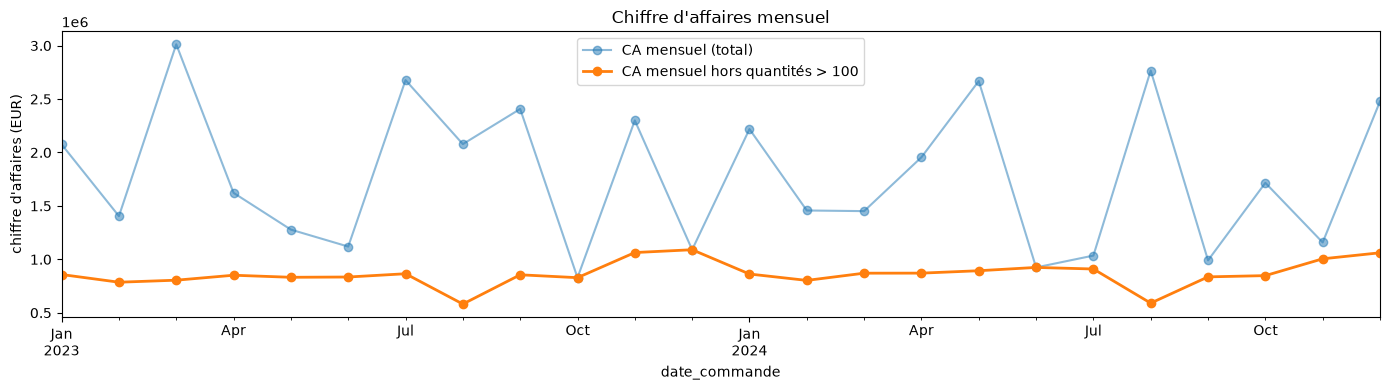

écrit : ventes_temporelles.parquet (16992, 37)


PosixPath('/Users/lucas/TP_Données_Coda/data/processed/ventes_temporelles.parquet')

In [14]:
# Q6. Agréger les ventes par semaine puis par mois. Tracer la série mensuelle du
#     chiffre d'affaires et commenter la saisonnalité observée.

# TODO
sales_by_date = sales.set_index('date_commande').sort_index()

weekly_revenue = sales_by_date['montant'].resample('W').sum()
monthly = sales_by_date['montant'].resample('ME').agg(['sum', 'size', 'median'])
monthly.columns = ['chiffre_affaires', 'nb_commandes', 'montant_median']

# Les quelques commandes aux quantités extrêmes (> 100) écrasent la série :
# on trace aussi le chiffre d'affaires sans elles pour lire la saisonnalité.
monthly['ca_hors_extremes'] = (sales_by_date.loc[sales_by_date['quantite'] <= 100, 'montant']
                               .resample('ME').sum())

print('Semaines :', len(weekly_revenue), '| CA hebdomadaire moyen :', round(weekly_revenue.mean(), 2))
print(monthly.round(0))

fig, ax = plt.subplots(figsize=(14, 4))
monthly['chiffre_affaires'].plot(ax=ax, marker='o', alpha=0.5, label='CA mensuel (total)')
monthly['ca_hors_extremes'].plot(ax=ax, marker='o', linewidth=2, label='CA mensuel hors quantités > 100')
ax.set_ylabel("chiffre d'affaires (EUR)")
ax.set_title("Chiffre d'affaires mensuel")
ax.legend()
plt.tight_layout()
plt.show()
# Commentaire : la série totale est très irrégulière, car un mois qui contient une ou
# deux commandes de plusieurs centaines d'unités double son CA. Une fois ces commandes
# isolées, une saisonnalité nette et identique sur les deux années apparaît :
#   - un creux en août (environ 30 % de commandes en moins : congés d'été) ;
#   - un pic en novembre-décembre (même volume de commandes, mais un panier plus élevé :
#     achats de fin d'année) ;
#   - un niveau stable le reste de l'année, autour de 850 000 EUR par mois.

# Export du jeu enrichi de ses variables temporelles, pour les séances suivantes
save_dataset(sales, 'ventes_temporelles')

---
## Livrable de la séance

- la fonction `parse_dates` avec son rapport de conversion, dans `src/` ;
- le jeu de ventes enrichi de ses variables temporelles ;
- les deux fonctions de détection d'anomalies de capteur (panne et blocage) ;
- un graphique commenté de la saisonnalité mensuelle.